# 01 · UCI Cardiotocography: аудит и подготовка признаков

## Кратко

Официальная книга UCI содержит **2126 сегментов КТГ, 21 признак и две экспертные метки**. Из признаков 20 измеряемых числовых; `Tendency` — кодированная категория (−1, 0, 1). В опубликованных сегментах нет пропусков. Сильная асимметрия и масса нулей есть у `FM`, `DS`, `DP`, `ALTV`, `Nzeros` и `Variance`; поэтому для разных групп признаков ниже применяются разные преобразования. Первичная таблица сохраняет исходные значения, а параметры масштабирования обучаются **только на train**. Так как обучающих пропусков нет, маски и импутация не добавляются: сохранённый преобразователь отклоняет новые пропуски как неподтверждённый режим входа.

Это учебный benchmark экспертной классификации КТГ, а не база исходов беременности или клинически проверенный прогноз. Повторные сегменты одного исходного файла остаются в одной выборке.

## Контекст и метод

Источник: [UCI Cardiotocography](https://archive.ics.uci.edu/dataset/193/cardiotocography), DOI [10.24432/C51S4N](https://doi.org/10.24432/C51S4N), лицензия CC BY 4.0. Читаем сохранённый в проекте официальный `CTG.xls` напрямую; интернет для повторного запуска не нужен. На листе **Data** находятся опубликованные частотные признаки, на листе **Raw Data** — идентификаторы исходного файла и сегмента. Сопоставление листов по порядку разрешено только после проверки совпадения 17 общих полей для каждой строки.

### Ключевые допущения

- Единица анализа — сегмент КТГ; `FileName` объединяет сегменты одной записи. Уникального идентификатора женщины нет, поэтому независимость по пациенткам доказать нельзя.
- `NSP` (1/2/3) — основной учебный исход; `CLASS` (1–10) — **другая метка**, исключённая из признаков. Обе метки сохраняются в первичной таблице.
- Числовые коды не определяют тип автоматически: `Tendency` — категория, а редко ненулевые `DS` и `DP` остаются измерениями частоты событий.
- Выбросы не удаляем автоматически: крайние значения могут содержать патологический сигнал. Не балансируем классы до разбиения.

## 1. Настройка и источник

In [4]:
from pathlib import Path
from hashlib import sha256
import json
import sys
import sklearn
from zipfile import ZipFile
from shutil import copyfileobj

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Binarizer, FunctionTransformer, MaxAbsScaler, OneHotEncoder, RobustScaler

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.features.ctg_preprocessing import CTGInputGuard
SOURCE = PROJECT_ROOT / 'data/external/uci_cardiotocography/1.0.0/files/CTG.xls'
ARCHIVE = PROJECT_ROOT / 'data/external/uci_cardiotocography/1.0.0/cardiotocography.zip'
OUTPUT = PROJECT_ROOT / 'data/processed/ctg_uci'
OUTPUT.mkdir(parents=True, exist_ok=True)
EXPECTED_SHA256 = 'd6aa62e82625e59f9d5b05bc8fc52af9ea67bdf2a23f1faca8511d5618fcb421'
if not SOURCE.exists():
    assert ARCHIVE.exists(), 'Сначала скачайте архив UCI по инструкции в README этой серии'
    SOURCE.parent.mkdir(parents=True, exist_ok=True)
    with ZipFile(ARCHIVE) as bundle, bundle.open('CTG.xls') as incoming, SOURCE.open('wb') as outgoing:
        copyfileobj(incoming, outgoing)
actual_hash = sha256(SOURCE.read_bytes()).hexdigest()
assert actual_hash == EXPECTED_SHA256, 'Исходный XLS отличается от зарегистрированного снимка UCI'

FEATURES = ['LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV',
            'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean',
            'Median', 'Variance', 'Tendency']
TARGETS = ['CLASS', 'NSP']
NUMERIC = [name for name in FEATURES if name != 'Tendency']
RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette=['#245b87', '#d99132', '#7d689b'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Источник: {SOURCE.relative_to(PROJECT_ROOT)} · SHA-256 {actual_hash[:16]}…')

Источник: data/external/uci_cardiotocography/1.0.0/files/CTG.xls · SHA-256 d6aa62e82625e59f…


## 2. Сопоставление листов и первичная таблица

In [6]:
# В Data первые 10 колонок — другая форма измерений, затем идут 21 опубликованный
# признак, а CLASS и NSP стоят в позициях 43 и 45 (нумерация Python с нуля).
data_sheet = pd.read_excel(SOURCE, sheet_name='Data', header=1, engine='xlrd')
selected = data_sheet.iloc[:, list(range(10, 31)) + [43, 45]].copy()
selected.columns = FEATURES + TARGETS
selected.insert(0, 'source_excel_row', selected.index + 3)
for column in FEATURES + TARGETS:
    selected[column] = pd.to_numeric(selected[column], errors='coerce')

valid_target = selected['NSP'].isin([1, 2, 3])
excluded_rows = selected.loc[~valid_target, 'source_excel_row'].tolist()
data = selected.loc[valid_target].reset_index(drop=True)
assert data['CLASS'].isin(range(1, 11)).all(), 'Неожиданный код CLASS'

raw_sheet = pd.read_excel(SOURCE, sheet_name='Raw Data', engine='xlrd')
metadata = raw_sheet.loc[raw_sheet['NSP'].isin([1, 2, 3])].reset_index(drop=True)
assert len(data) == len(metadata) == 2126
shared = ['LB', 'ASTV', 'MSTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max',
          'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance',
          'Tendency', 'CLASS', 'NSP']
for column in shared:
    assert np.allclose(data[column].to_numpy(dtype=float),
                       pd.to_numeric(metadata[column], errors='coerce').to_numpy(dtype=float),
                       equal_nan=True), f'Листы не совпадают по {column}'
assert metadata[['FileName', 'SegFile']].notna().all().all()
assert metadata['SegFile'].is_unique

data.insert(1, 'source_file', metadata['FileName'].astype(str))
data.insert(2, 'segment_file', metadata['SegFile'].astype(str))
data.insert(3, 'recorded_date', pd.to_datetime(metadata['Date'], errors='coerce'))
assert data['recorded_date'].notna().all()
data[TARGETS] = data[TARGETS].astype('int16')
data['Tendency'] = data['Tendency'].astype('Int8')
print(f'Строк листа Data: {len(selected)}; служебных строк исключено: {len(excluded_rows)} ({excluded_rows})')
print(f'Сегментов: {len(data)}; исходных файлов: {data.source_file.nunique()}')
display(data[['source_excel_row', 'source_file', 'segment_file', 'LB', 'Tendency', 'CLASS', 'NSP']].head())

Строк листа Data: 2129; служебных строк исключено: 3 ([2129, 2130, 2131])
Сегментов: 2126; исходных файлов: 352


,source_excel_row,source_file,segment_file,LB,Tendency,CLASS,NSP
0,3,Variab10.txt,CTG0001.txt,120.0,1,9,2
1,4,Fmcs_1.txt,CTG0002.txt,132.0,0,6,1
2,5,Fmcs_1.txt,CTG0003.txt,133.0,0,6,1
3,6,Fmcs_1.txt,CTG0004.txt,134.0,1,6,1
4,7,Fmcs_1.txt,CTG0005.txt,132.0,1,2,1


### Проверки качества и повторов

In [8]:
# Отчёт до импутации: ошибки типов видны как NaN, а не скрываются удалением строк.
quality = pd.DataFrame({
    'missing': data[FEATURES].isna().sum(),
    'missing_pct': data[FEATURES].isna().mean().mul(100).round(2),
    'unique': data[FEATURES].nunique(dropna=True),
    'zero_pct': data[FEATURES].eq(0).mean().mul(100).round(1),
})
assert np.isfinite(data[NUMERIC].to_numpy(dtype=float)[~data[NUMERIC].isna().to_numpy()]).all()
assert data['Tendency'].dropna().isin([-1, 0, 1]).all()
assert (data[[c for c in NUMERIC if c not in ['Tendency']]] < 0).sum().sum() == 0
assert data[['ASTV', 'ALTV']].le(100).all().all()
assert (data['Width'] == data['Max'] - data['Min']).all()

# Повторяемость определяется по 21 признаку, без обеих меток.
data.insert(4, 'feature_duplicate_group', data.groupby(FEATURES, dropna=False, sort=False).ngroup().astype('int32'))
duplicate_groups = data.groupby('feature_duplicate_group').agg(
    rows=('NSP', 'size'), files=('source_file', 'nunique'),
    nsp_values=('NSP', 'nunique'), class_values=('CLASS', 'nunique'))
assert duplicate_groups['files'].max() == 1, 'Одинаковые признаки встречаются в разных файлах; требуется объединить группы для split'
print(f'Пропусков в признаках: {int(quality.missing.sum())}; полных дублей: {int(data.duplicated(FEATURES + TARGETS).sum())}')
print(f'Повторных векторов признаков: {int(data.duplicated(FEATURES).sum())}; групп с несовпадающими метками: {int(((duplicate_groups.nsp_values > 1) | (duplicate_groups.class_values > 1)).sum())}')
display(quality.sort_values(['missing_pct', 'zero_pct'], ascending=False).head(10))

Пропусков в признаках: 0; полных дублей: 11
Повторных векторов признаков: 14; групп с несовпадающими метками: 3


,missing,missing_pct,unique,zero_pct
DS,0,0.0,8,99.7
DP,0,0.0,166,91.6
Nzeros,0,0.0,9,76.4
FM,0,0.0,696,61.7
ALTV,0,0.0,87,58.3
DL,0,0.0,751,57.9
Tendency,0,0.0,3,52.4
AC,0,0.0,1015,41.9
UC,0,0.0,1315,15.6
Variance,0,0.0,133,8.8


### Типы признаков и сохранение первичных данных

Порог низкой кардинальности (≤10 уникальных значений) помечает `DS`, `Nzeros` и `Tendency` как кандидатов. По смыслу `DS` — частота событий, `Nzeros` — счётчик, а `Tendency` кодирует направление и пойдёт в one-hot. `CLASS` и `NSP` — метки. Остальные поля являются числовыми измерениями, даже если имеют мало уникальных значений. `source_file`, `segment_file`, дата, номер строки и группа повторов — только метаданные. Первичный Parquet сохраняет исходные числовые значения и пропуски без импутации.

In [10]:
roles = quality.copy()
roles['low_cardinality_candidate'] = roles['unique'].le(10)
roles['role'] = ['categorical' if c == 'Tendency' else 'numeric' for c in roles.index]
print('Кандидаты по кардинальности ≤10:', roles.index[roles.low_cardinality_candidate].tolist())
display(roles[['role', 'low_cardinality_candidate', 'unique', 'zero_pct', 'missing_pct']])
primary_path = OUTPUT / 'ctg_primary.parquet'
data.to_parquet(primary_path, index=False)
print(f'Первичная таблица: {primary_path.relative_to(PROJECT_ROOT)} · {data.shape[0]} × {data.shape[1]}')

Кандидаты по кардинальности ≤10: ['DS', 'Nzeros', 'Tendency']
Первичная таблица: data/processed/ctg_uci/ctg_primary.parquet · 2126 × 28


,role,low_cardinality_candidate,unique,zero_pct,missing_pct
LB,numeric,False,48,0.0,0.0
AC,numeric,False,1015,41.9,0.0
FM,numeric,False,696,61.7,0.0
UC,numeric,False,1315,15.6,0.0
DL,numeric,False,751,57.9,0.0
DS,numeric,True,8,99.7,0.0
DP,numeric,False,166,91.6,0.0
ASTV,numeric,False,75,0.0,0.0
MSTV,numeric,False,57,0.0,0.0
ALTV,numeric,False,87,58.3,0.0


## 3. Разбиение по исходным файлам и контроль долей классов

Стратификация подбирает grouped-фолды по двум разметкам. Под балансом здесь понимается близость **долей каждого класса** в train, validation и test к полному набору. Неравные естественные частоты остаются в test; веса для редких `NSP` сохраняются отдельно и используются только при обучении.

In [12]:
# Пять grouped-фолдов по CLASS. Из них фиксированным правилом выбираем тот,
# где доли ОБЕИХ меток (NSP и CLASS) ближе к исходному набору.
# Повторяем 80/20 внутри train+validation: итог около 64/16/20.
def choose_grouped_fold(frame, seed):
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    candidates = list(splitter.split(frame[FEATURES], frame['CLASS'], frame['source_file']))

    def score(candidate):
        keep_idx, hold_idx = candidate
        gaps = []
        for target in TARGETS:
            overall = frame[target].value_counts(normalize=True).sort_index()
            for indices in (keep_idx, hold_idx):
                share = frame.iloc[indices][target].value_counts(normalize=True).reindex(overall.index, fill_value=0)
                gaps.append(float((share - overall).abs().max()))
        return (max(gaps), sum(gaps), abs(len(hold_idx) / len(frame) - 0.2))

    chosen = min(range(len(candidates)), key=lambda i: score(candidates[i]))
    return candidates[chosen], chosen

(trainval_idx, test_idx), outer_fold = choose_grouped_fold(data, RANDOM_STATE)
trainval = data.iloc[trainval_idx]
(train_local, val_local), inner_fold = choose_grouped_fold(trainval, RANDOM_STATE + 1)
train_idx, val_idx = trainval_idx[train_local], trainval_idx[val_local]
split = pd.Series(index=data.index, dtype='string', name='split')
for name, indices in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]:
    split.iloc[indices] = name
assert split.notna().all()
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert set(data.loc[split == left, 'source_file']).isdisjoint(data.loc[split == right, 'source_file'])
    assert set(data.loc[split == left, 'feature_duplicate_group']).isdisjoint(data.loc[split == right, 'feature_duplicate_group'])
print(f'Выбранные grouped-фолды: внешний {outer_fold}, внутренний {inner_fold}')
for target in ['NSP', 'CLASS']:
    counts = pd.crosstab(split, data[target]).reindex(['train', 'validation', 'test'])
    share = counts.div(counts.sum(axis=1), axis=0).mul(100)
    overall = data[target].value_counts(normalize=True).sort_index().mul(100)
    max_gap_pp = (share - overall).abs().to_numpy().max()
    print(f'{target}: максимальное отклонение доли от полного набора = {max_gap_pp:.2f} п.п.')
    display(counts)
    display(share.round(2))
    assert max_gap_pp < 1.0, f'Недостаточная стратификация {target}'
split_frame = data[['source_excel_row', 'source_file', 'segment_file', 'feature_duplicate_group', 'CLASS', 'NSP']].copy()
split_frame.insert(1, 'split', split)
split_frame.to_parquet(OUTPUT / 'ctg_splits.parquet', index=False)

# Для будущей модели: равные суммарные веса классов NSP внутри train.
# Test и validation не пересэмплируются и не меняют исходную частоту классов.
train_counts = data.loc[split == 'train', 'NSP'].value_counts().sort_index()
train_class_weights = {int(label): float(len(train_idx) / (len(train_counts) * count))
                       for label, count in train_counts.items()}
train_weights = data.loc[split == 'train', ['source_excel_row', 'NSP']].copy()
train_weights['sample_weight'] = train_weights['NSP'].map(train_class_weights)
train_weights.to_parquet(OUTPUT / 'train_sample_weights.parquet', index=False)
print('Веса NSP для train:', {k: round(v, 3) for k, v in train_class_weights.items()})

Выбранные grouped-фолды: внешний 3, внутренний 0
NSP: максимальное отклонение доли от полного набора = 0.39 п.п.
CLASS: максимальное отклонение доли от полного набора = 0.27 п.п.
Веса NSP для train: {1: 0.429, 2: 2.373, 3: 4.048}


NSP,1,2,3
split,,,
train,1057,191,112
validation,266,46,29
test,332,58,35


NSP,1,2,3
split,,,
train,77.72,14.04,8.24
validation,78.01,13.49,8.50
test,78.12,13.65,8.24


CLASS,1,2,3,4,5,6,7,8,9,10
split,,,,,,,,,,
train,246,370,35,51,47,212,160,69,44,126
validation,62,93,8,13,11,53,41,17,12,31
test,76,116,10,17,14,67,51,21,13,40


CLASS,1,2,3,4,5,6,7,8,9,10
split,,,,,,,,,,
train,18.09,27.21,2.57,3.75,3.46,15.59,11.76,5.07,3.24,9.26
validation,18.18,27.27,2.35,3.81,3.23,15.54,12.02,4.99,3.52,9.09
test,17.88,27.29,2.35,4.00,3.29,15.76,12.00,4.94,3.06,9.41


## 4. Распределения числовых признаков

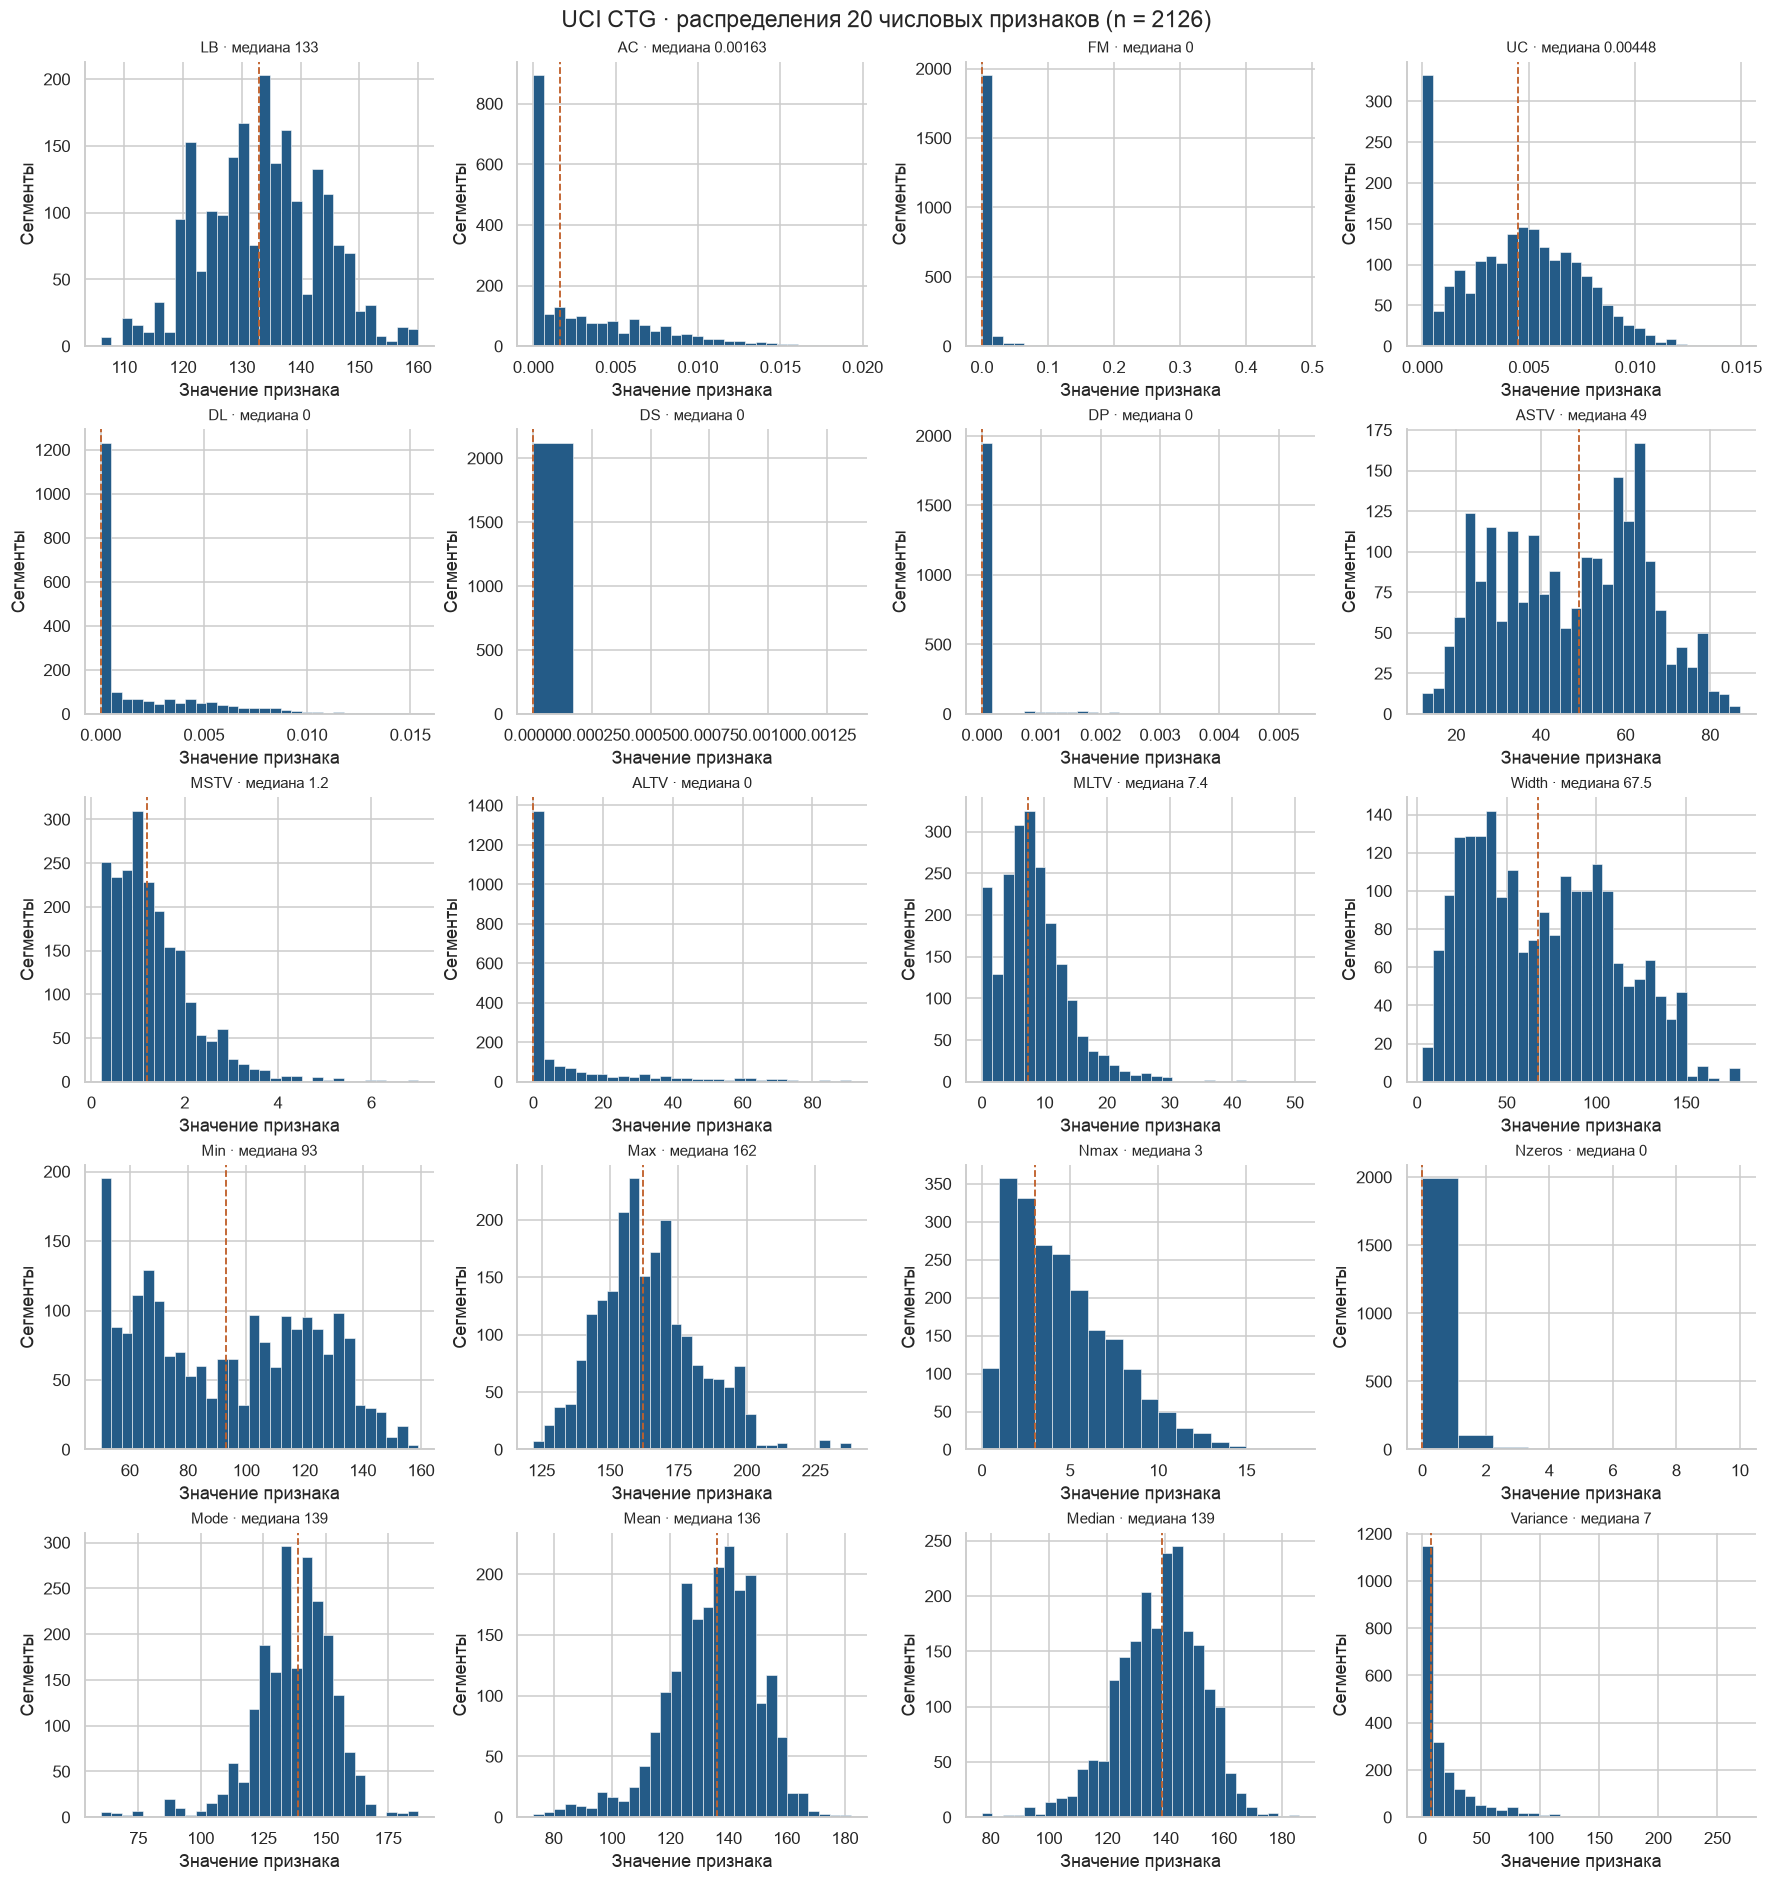

In [14]:
fig, axes = plt.subplots(5, 4, figsize=(16, 17), constrained_layout=True)
for ax, column in zip(axes.flat, NUMERIC):
    values = data[column].dropna()
    ax.hist(values, bins=min(30, max(8, values.nunique())), color='#245b87', edgecolor='white', linewidth=.35)
    ax.axvline(values.median(), color='#c0602a', linestyle='--', linewidth=1.2)
    ax.set_title(f'{column} · медиана {values.median():.3g}', fontsize=10)
    ax.set_ylabel('Сегменты')
    ax.set_xlabel('Значение признака')
fig.suptitle('UCI CTG · распределения 20 числовых признаков (n = 2126)', fontsize=15)
plt.show()

### Нули, асимметрия и крайние значения

,zero_pct,skew,q01,median,q99,max,above_1_5_iqr_pct
DS,99.671,17.812,0.00,0.000,0.000,0.001,0.329
FM,61.665,7.812,0.00,0.000,0.339,0.481,15.851
DP,91.627,4.279,0.00,0.000,0.003,0.005,8.373
Nzeros,76.388,3.920,0.00,0.000,3.000,10.000,23.612
Variance,8.796,3.220,0.00,7.000,135.500,269.000,8.655
ALTV,58.325,2.195,0.00,0.000,77.750,91.000,14.534
DL,57.902,1.722,0.00,0.000,0.012,0.015,5.550
MSTV,0.000,1.657,0.20,1.200,4.400,7.000,3.293
MLTV,6.444,1.332,0.00,7.400,26.300,50.700,3.340
AC,41.910,1.210,0.00,0.002,0.015,0.019,1.411


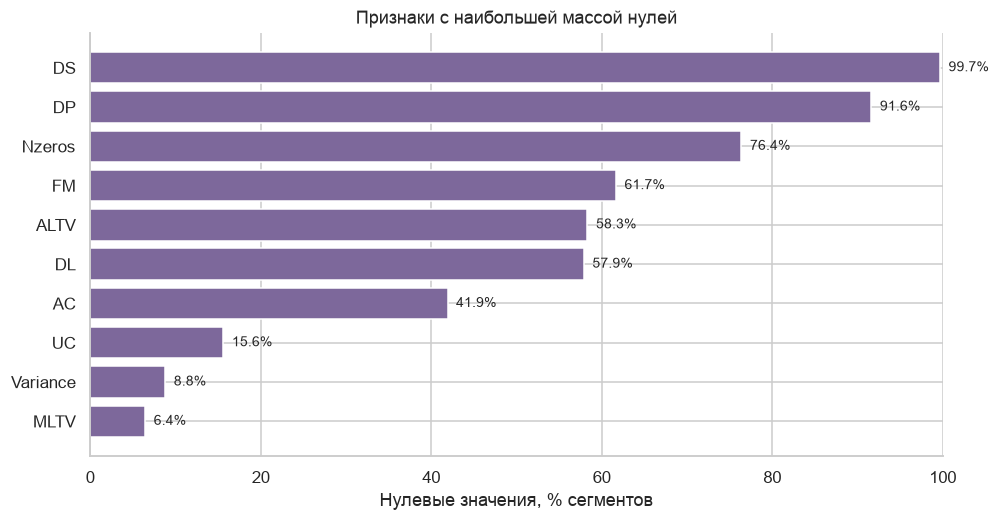

In [16]:
profile = pd.DataFrame(index=NUMERIC)
profile['zero_pct'] = data[NUMERIC].eq(0).mean().mul(100)
profile['skew'] = data[NUMERIC].skew()
profile['q01'] = data[NUMERIC].quantile(.01)
profile['median'] = data[NUMERIC].median()
profile['q99'] = data[NUMERIC].quantile(.99)
profile['max'] = data[NUMERIC].max()
q1, q3 = data[NUMERIC].quantile(.25), data[NUMERIC].quantile(.75)
iqr = q3 - q1
profile['above_1_5_iqr_pct'] = data[NUMERIC].gt(q3 + 1.5 * iqr).mean().mul(100)
display(profile.sort_values('skew', ascending=False).round(3))

fig, ax = plt.subplots(figsize=(10, 5))
shown = profile.sort_values('zero_pct', ascending=False).head(10).sort_values('zero_pct')
ax.barh(shown.index, shown.zero_pct, color='#7d689b')
ax.set(xlabel='Нулевые значения, % сегментов', title='Признаки с наибольшей массой нулей')
ax.set_xlim(0, 100)
for i, value in enumerate(shown.zero_pct):
    ax.text(value + 1, i, f'{value:.1f}%', va='center', fontsize=9)
plt.show()

### Категория и разметка

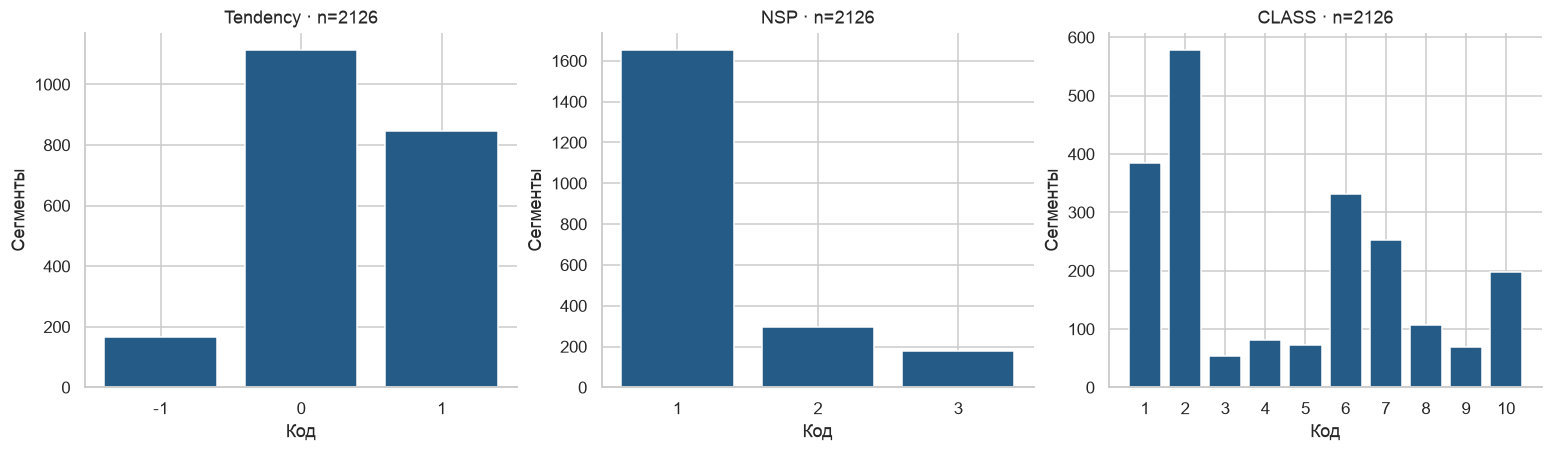

,segments
NSP,
normal,1655
suspect,295
pathologic,176


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, column in zip(axes, ['Tendency', 'NSP', 'CLASS']):
    counts = data[column].value_counts().sort_index()
    ax.bar([str(v) for v in counts.index], counts.values, color='#245b87')
    ax.set(title=f'{column} · n={len(data)}', xlabel='Код', ylabel='Сегменты')
plt.show()
display(data['NSP'].value_counts().sort_index().rename({1:'normal', 2:'suspect', 3:'pathologic'}).to_frame('segments'))

## 5. Решения по подготовке

- **Пропуски и маски.** Во всех 21 признаках опубликованного снимка отсутствуют пропуски. Маска каждого поля была бы константой 0, а медианная импутация не могла бы быть проверена на реальных пропусках. Поэтому ни маски, ни импутация в модельную матрицу не добавляются. Сохранённый преобразователь отвергает новые пропуски, неизвестные коды `Tendency` и нарушение доменных правил; для такого источника потребуется отдельный аудит и переобучение.
- **Плотные измерения:** `RobustScaler` (медиана и IQR). Крайние наблюдения не обрезаются.
- **Асимметричные измерения:** деление на обучающий IQR → `log1p` → `RobustScaler`. Для малых частот `AC`, `FM`, `DL` нормировка перед логарифмом сжимает хвост. Логарифм применяется только к неотрицательным данным.
- **Редкие `DP` и `Nzeros`:** `log1p` → `MaxAbsScaler`, плюс индикатор наличия (>0). Их IQR равен нулю; ненулевые значения не обрезаются. `MaxAbsScaler` сохраняет нуль и обучается только на train, но зависит от максимума — параметры сохранены для аудита.
- **`Width`:** точно равен `Max−Min` для каждой строки. В масштабированной матрице для линейных и дистанционных моделей оставлены `Min` и `Max`, чтобы не дублировать одну и ту же информацию; исходный `Width` сохранён в первичной таблице для аудита и возможного отдельного сравнения. Текущие CatBoost-процедуры 02/03 также исключают `Width`, как и линейные/дистанционные модели.
- **`DS`:** только 7 ненулевых сегментов из 2 исходных файлов в train. Этого недостаточно для надёжной оценки эффекта; `DS` сохраняется в первичной таблице и исключается из готовой матрицы. На validation/test ненулевых `DS` нет, поэтому влияние этого признака здесь невозможно проверить.
- **`Tendency`:** one-hot с отказом на неизвестном коде. `CLASS`, `NSP` и метаданные не входят в модельную матрицу.

Это одна воспроизводимая схема для линейных и дистанционных моделей, не универсально оптимальный скейлер. Деревья можно сравнивать на неизменённой первичной таблице с тем же разбиением, с отдельной проверкой влияния `Width` и также исключив `DS` в основном baseline.

### Профиль train для выбора преобразований

Общие графики выше описывают весь опубликованный набор. Выбор семейств преобразований опирается на профиль train; validation и test не используются для подбора рецепта или его параметров.

In [21]:
train_values = data.loc[split == 'train', NUMERIC]
train_profile = pd.DataFrame({
    'zero_pct': train_values.eq(0).mean().mul(100),
    'skew': train_values.skew(),
    'q25': train_values.quantile(.25),
    'q75': train_values.quantile(.75),
})
train_profile['iqr'] = train_profile['q75'] - train_profile['q25']
display(train_profile.sort_values('zero_pct', ascending=False).round(3))

positive_sources = pd.Series({column: data.loc[(split == 'train') & data[column].gt(0), 'source_file'].nunique()
                              for column in NUMERIC}, name='train_files_with_positive_value')
display(positive_sources.sort_values().head(8).to_frame())
assert positive_sources['DS'] == 2 and positive_sources['DP'] >= 20


,zero_pct,skew,q25,q75,iqr
DS,99.485,14.214,0.000,0.000,0.000
DP,92.132,4.428,0.000,0.000,0.000
Nzeros,75.662,4.119,0.000,0.000,0.000
FM,62.868,7.007,0.000,0.002,0.002
DL,57.426,1.753,0.000,0.003,0.003
ALTV,57.132,2.285,0.000,10.250,10.250
AC,40.809,1.192,0.000,0.006,0.006
UC,15.000,0.237,0.002,0.006,0.005
Variance,7.426,3.468,2.000,24.000,22.000
MLTV,6.176,1.170,4.775,11.225,6.450


,train_files_with_positive_value
DS,2
DP,24
Nzeros,102
DL,106
FM,122
ALTV,134
AC,162
UC,181


### Корреляции и структурная избыточность на train

Сильные связи оцениваются ранговой корреляцией Спирмена только на train. `Width = Max − Min` проверено точно для всех строк. Все признаки остаются в первичной таблице. В основной модельной схеме исключены `Width` (точная избыточность) и `DS` (недостаточная поддержка исходными файлами); прочие коррелированные измерения сохранены, поскольку их связь не является тождеством.

Пар с |ρ| ≥ 0.8: 7; Width = Max − Min: True


,feature_1,feature_2,spearman_r
185,Mode,Median,0.963
187,Mean,Median,0.952
184,Mode,Mean,0.908
154,Width,Min,-0.908
161,Width,Variance,0.818
17,LB,Median,0.817
15,LB,Mode,0.802


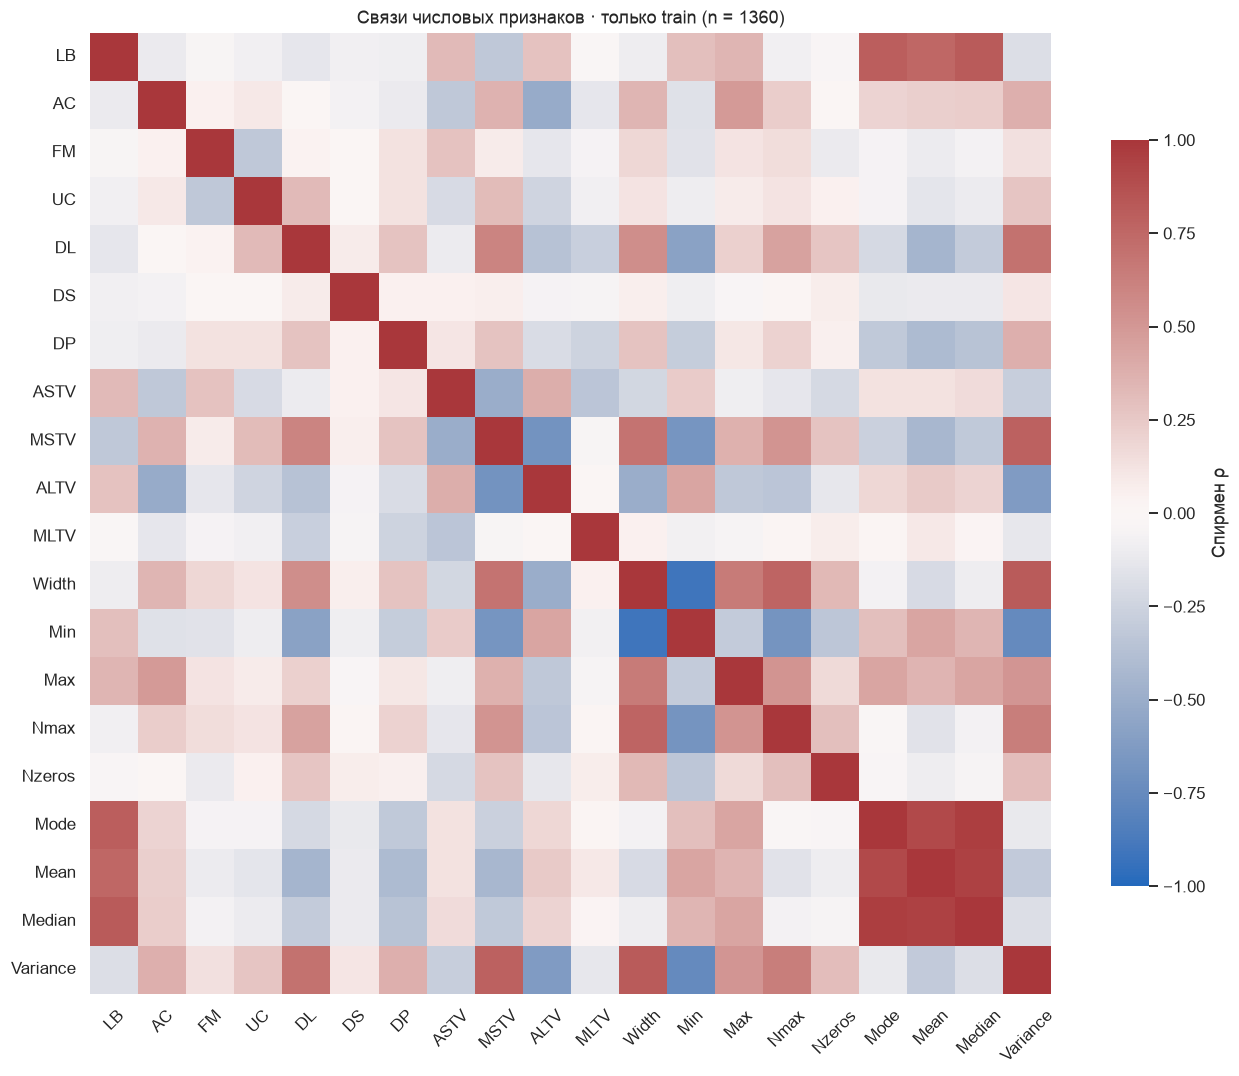

In [23]:
corr = train_values.corr(method='spearman')
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
strong_pairs = upper.stack().rename('spearman_r').reset_index()
strong_pairs.columns = ['feature_1', 'feature_2', 'spearman_r']
strong_pairs = strong_pairs.loc[strong_pairs.spearman_r.abs() >= 0.8]
strong_pairs = strong_pairs.reindex(strong_pairs.spearman_r.abs().sort_values(ascending=False).index)
display(strong_pairs.head(15).round(3))
print(f'Пар с |ρ| ≥ 0.8: {len(strong_pairs)}; Width = Max − Min: {bool((data.Width == data.Max - data.Min).all())}')
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, ax=ax, cmap='vlag', center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={'label': 'Спирмен ρ', 'shrink': .75})
ax.set_title(f'Связи числовых признаков · только train (n = {len(train_values)})')
ax.tick_params(axis='x', labelrotation=45)
plt.tight_layout()
plt.show()

### Преобразователь, обученный на train

In [25]:
DENSE = ['LB', 'UC', 'ASTV', 'Min', 'Max', 'Nmax', 'Mode', 'Mean', 'Median']
SKEWED = ['AC', 'FM', 'DL', 'MSTV', 'ALTV', 'MLTV', 'Variance']
RARE = ['DP', 'Nzeros']
EXCLUDED_FROM_MODEL = ['DS', 'Width']  # редкий DS и точная линейная избыточность Width
assert set(DENSE + SKEWED + RARE + EXCLUDED_FROM_MODEL) == set(NUMERIC)
assert train_profile.loc[SKEWED, 'iqr'].gt(0).all()
assert train_profile.loc[RARE, 'iqr'].eq(0).all()

column_preprocessor = ColumnTransformer(
    transformers=[
        ('dense', RobustScaler(), DENSE),
        ('skewed', Pipeline([('iqr_units', RobustScaler(with_centering=False)),
                             ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                             ('scale', RobustScaler())]), SKEWED),
        ('rare', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                           ('scale', MaxAbsScaler())]), RARE),
        ('rare_present', Binarizer(threshold=0.0), RARE),
        ('tendency', OneHotEncoder(handle_unknown='error', sparse_output=False), ['Tendency']),
    ], remainder='drop', verbose_feature_names_out=True)
preprocessor = Pipeline([('input_guard', CTGInputGuard()), ('columns', column_preprocessor)])

X_train = data.loc[split == 'train', FEATURES]
preprocessor.fit(X_train)
names = preprocessor.get_feature_names_out()
assert len(names) == len(set(names))
assert not any('DS' in name for name in names)
matrices = {}
for name in ['train', 'validation', 'test']:
    transformed = preprocessor.transform(data.loc[split == name, FEATURES])
    assert np.isfinite(transformed).all(), f'Не конечные значения в {name}'
    matrix = pd.DataFrame(transformed, columns=names, index=data.index[split == name])
    matrix.insert(0, 'source_excel_row', data.loc[split == name, 'source_excel_row'].to_numpy())
    matrices[name] = matrix
    matrix.to_parquet(OUTPUT / f'X_{name}.parquet', index=False)

# Оба артефакта содержат ровно те параметры, которые были оценены на train.
joblib.dump(preprocessor, OUTPUT / 'preprocessor.joblib')
fitted = preprocessor.named_steps['columns'].named_transformers_
assert np.allclose(fitted['dense'].center_, X_train[DENSE].median().to_numpy(dtype=float))
assert np.allclose(fitted['dense'].scale_, (X_train[DENSE].quantile(.75) - X_train[DENSE].quantile(.25)).to_numpy(dtype=float))
assert np.allclose(fitted['skewed'].named_steps['iqr_units'].scale_,
                   (X_train[SKEWED].quantile(.75) - X_train[SKEWED].quantile(.25)).to_numpy(dtype=float))
scalers = {
    'dense': fitted['dense'],
    'skewed_iqr_units': fitted['skewed'].named_steps['iqr_units'],
    'skewed_final': fitted['skewed'].named_steps['scale'],
    'rare': fitted['rare'].named_steps['scale'],
}
joblib.dump(scalers, OUTPUT / 'scalers.joblib')
scaler_parameters = {
    'dense': {'features': DENSE, 'median': scalers['dense'].center_.tolist(),
              'iqr': scalers['dense'].scale_.tolist()},
    'skewed_iqr_units': {'features': SKEWED, 'iqr': scalers['skewed_iqr_units'].scale_.tolist()},
    'skewed_final': {'features': SKEWED, 'median': scalers['skewed_final'].center_.tolist(),
                     'iqr': scalers['skewed_final'].scale_.tolist()},
    'rare': {'features': RARE, 'max_abs_after_log1p': scalers['rare'].max_abs_.tolist()},
}
(OUTPUT / 'scaler_parameters.json').write_text(json.dumps(scaler_parameters, ensure_ascii=False, indent=2), encoding='utf-8')
restored = joblib.load(OUTPUT / 'preprocessor.joblib')
restored_scalers = joblib.load(OUTPUT / 'scalers.joblib')
assert np.allclose(restored.transform(X_train), preprocessor.transform(X_train))
assert np.allclose(restored_scalers['dense'].center_, scalers['dense'].center_)
print(f'Признаков после преобразования: {len(names)}; скейлеры и весь преобразователь сохранены в {OUTPUT.relative_to(PROJECT_ROOT)}')
display(pd.DataFrame({'model_feature': names}).head(35))

Признаков после преобразования: 23; скейлеры и весь преобразователь сохранены в data/processed/ctg_uci


,model_feature
0,dense__LB
1,dense__UC
2,dense__ASTV
3,dense__Min
4,dense__Max
5,dense__Nmax
6,dense__Mode
7,dense__Mean
8,dense__Median
9,skewed__AC


### Контроль преобразований и выходной контракт

Сохранены первичная таблица, разбиение, три матрицы, преобразователь, скейлеры и manifest.json


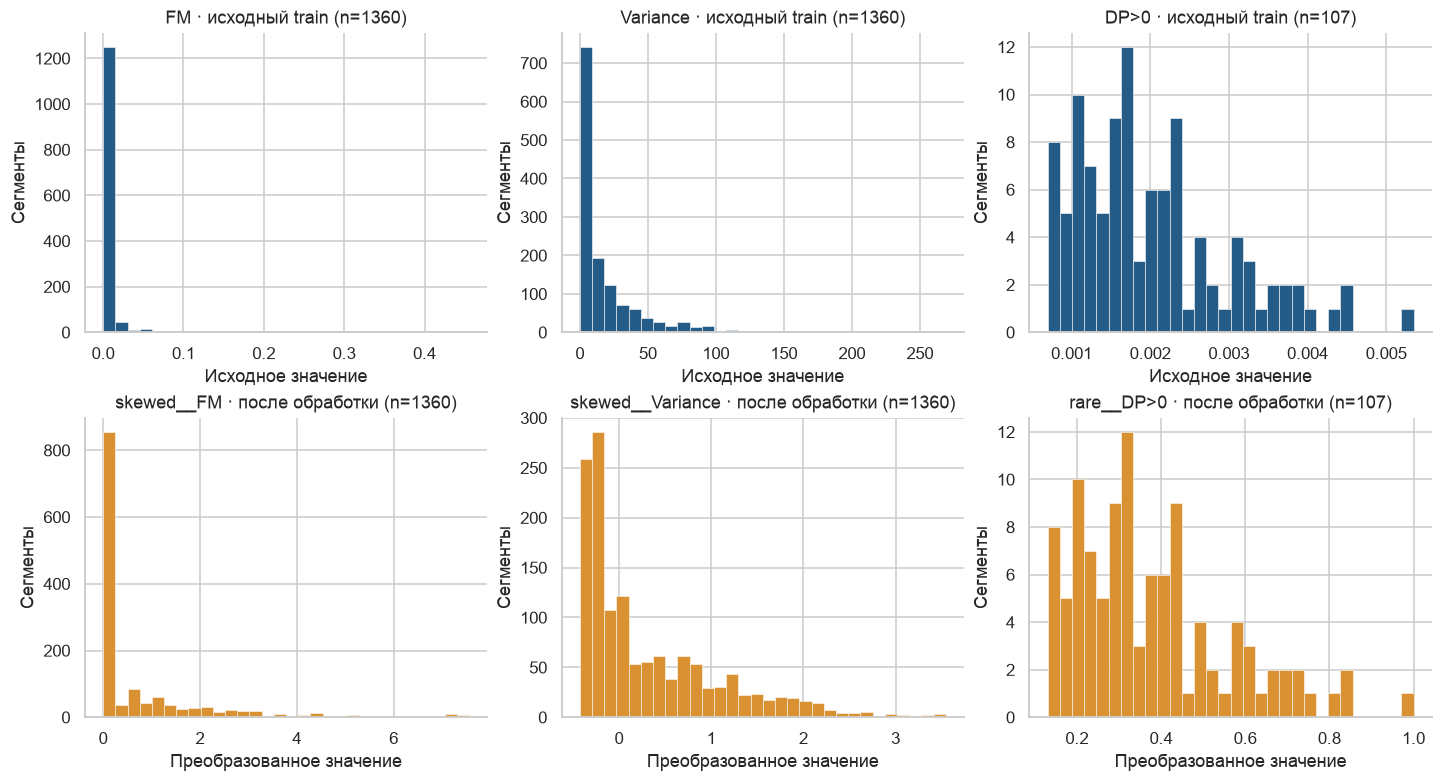

In [27]:
# Визуальный контроль нескольких представительных колонок без использования меток.
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for ax, column in zip(axes[0], ['FM', 'Variance', 'DP']):
    values = X_train[column].dropna()
    if column == 'DP':
        values = values[values > 0]  # нулевая масса показана отдельным графиком выше
    ax.hist(values, bins=30, color='#245b87', edgecolor='white', linewidth=.35)
    ax.set(title=f'{column}{">0" if column == "DP" else ""} · исходный train (n={len(values)})',
           xlabel='Исходное значение', ylabel='Сегменты')
for ax, column in zip(axes[1], ['skewed__FM', 'skewed__Variance', 'rare__DP']):
    values = matrices['train'][column]
    if column == 'rare__DP':
        values = values[values > 0]
    ax.hist(values, bins=30, color='#d99132', edgecolor='white', linewidth=.35)
    ax.set(title=f'{column}{">0" if column == "rare__DP" else ""} · после обработки (n={len(values)})',
           xlabel='Преобразованное значение', ylabel='Сегменты')
plt.show()

manifest = {
    'source': str(SOURCE.relative_to(PROJECT_ROOT)), 'source_sha256': actual_hash,
    'primary': str(primary_path.relative_to(PROJECT_ROOT)), 'rows': len(data),
    'features': FEATURES, 'numeric': NUMERIC, 'categorical': ['Tendency'],
    'model_excluded_features': {'DS': 'nonzero in only 2 source files on train',
                                'Width': 'exactly Max - Min for every row'},
    'missing_policy': 'reject: no feature missingness observed in source or train; no fitted missingness mask or imputer',
    'sklearn_version': sklearn.__version__, 'pandas_version': pd.__version__,
    'saved_artifact_sha256': {name: sha256((OUTPUT / name).read_bytes()).hexdigest()
                              for name in ['preprocessor.joblib', 'scalers.joblib', 'scaler_parameters.json']},
    'targets': TARGETS, 'main_target': 'NSP',
    'metadata_not_features': ['source_excel_row', 'source_file', 'segment_file', 'recorded_date', 'feature_duplicate_group'],
    'split_seed': RANDOM_STATE, 'split_group': 'source_file',
    'selected_folds': {'outer': outer_fold, 'inner': inner_fold},
    'balance_max_gap_pp': 1.0, 'nsp_train_class_weights': train_class_weights,
    'split_counts': {k: int(v) for k, v in split.value_counts().items()},
    'transformed_features': names.tolist(),
    'preprocessing': {'dense': DENSE, 'skewed': SKEWED, 'rare': RARE,
                      'scaler_artifact': 'scalers.joblib', 'scaler_parameters': 'scaler_parameters.json',
                      'categorical': ['Tendency'], 'fitted_on': 'train_only'},
}
(OUTPUT / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
assert sum(manifest['split_counts'].values()) == len(data)
assert all(len(matrices[k]) == manifest['split_counts'][k] for k in matrices)
print('Сохранены первичная таблица, разбиение, три матрицы, преобразователь, скейлеры и manifest.json')

## Выводы и дальнейшие шаги

В этой версии источника **2126 сегментов / 352 файла**, 21 исходный признак, ноль пропусков, **14 повторов feature-векторов** и **11 полных дублей**. Есть три группы с одинаковыми признаками и разными экспертными метками; их не следует удалять или переносить между частями набора автоматически. `NSP` неравномерен (1655 / 295 / 176). Особенно редок `DS`: всего 7 ненулевых сегментов из двух исходных файлов. Он оставлен в первичной таблице, но исключён из готовых модельных матриц; его влияние в этой выборке нельзя надёжно проверить. `DP` и `Nzeros` сохраняют отдельные признаки наличия и величины. В train сильно связаны `Mode`–`Median` (ρ=0.950) и `Mean`–`Median` (ρ=0.942); `Width` точно равен `Max−Min` и потому исключён из готовой масштабированной матрицы, но сохранён в первичных данных. Остальные высококоррелированные поля оставлены: их связь не является тождеством. Доли всех классов `NSP` и `CLASS` в каждой выборке отличаются от общего набора менее чем на 0,4 п.п.; веса редких классов рассчитаны только для train, а test сохраняет естественную частоту. Пропусков нет, поэтому маски и импутация не обучались; новый пропуск вызывает явный отказ. Скейлеры сохранены отдельно и в составе преобразователя. Значения нормализованы только в модельных матрицах; исходная первичная таблица остаётся пригодной для деревьев и дальнейшего аудита.

В текущей серии audited v2 сохранённое разбиение используется с 5×3 вложенным поиском на train; validation нужна для финальной калибровки/порога и архитектуры. Test уже просматривался и используется только для исследовательской перепроверки после фиксации; он не становится новой слепой когортой. Основные метрики — macro-F1, balanced accuracy, recall патологического класса и матрица ошибок. Результаты не являются клинической валидацией; возможная зависимость разных файлов от одной пациентки неизвестна.